---
title: "Viscosity of Binary Solutions"
subtitle: Determination of the Viscosity, Fluidity, and Solution Ideality of Methanol/Water, and Toluene/p-Xylene Mixtures
authors:
  - name: J. P. Sample
    email: jsample@hunter.cuny.edu
    affiliations:
      - ror: 00g2xk477
      - institution: CUNY – Hunter College
      - department: Chemistry
date: 2000-01-01
numbering:
  heading_2: true
  heading_3: true
---

## Purpose

By measuring and analyzing the viscosity of several mixture ratios of ideal (toluene/_p_-xylene) and nonideal (methanol/water) binary solutions and their components, the activation energy to viscous flow will be determined. 

## Introduction

Viscosity is a quantifiable, intrinsic physical property of liquids. The viscosity of a liquid is analogous to the flow resistances that are studied in the context of fluid mechanics. That is to say, in a practical context, the viscosity of a liquid is essentially its ability to resist flow through an apparatus. As a quantifiable property of a system, viscosity is commonly used to determine the quality (stickiness, thickness, etc.) of a given solution compared to another, such as commercial resins, oils, paints, etc. The viscosity of a solution is also useful as it provides information regarding the kinetics of reactions in the context of the diffusion of the reagents and products of a reaction in solution (the medium); invaluable information to physical chemists and materials scientists.

On a macroscopic level, the idea of viscosity can be interpreted as the frictional force between molecules as they move across each other via the flow of the liquid. The attractive intermolecular forces between the molecules that comprise the liquid must be overcome in order for the liquid to flow.

In this experiment, we measure the viscosities of binary solutions as they flow through a circular tube of small internal diameter, specifically an Ostwald viscometer. The flow of the solution though the capillary tube diameter follows Poiseuille’s law (eq. 1), which describes the volume flow rate based on the physical dimensions of the viscometer, the solution’s density (expressed as a pressure difference, as the hydrostatic pressure is proportional to the liquid density), and its viscosity. We also determine the fluidity of these mixtures, which are simply the reciprocal of the viscosity (eq. 2). We use the fluidities of the mixtures to determine the solution ideality. A solution mixture comprised of liquids that do not associate (or relatively weakly associate) is said to be ideal. The fluidity of an ideal mixture is additive (eq. 3), as the interaction energies of each of the constituents of the solution are independent and thus constant compared to the components in a pure solution. In contrast, a non-ideal solution has components that do strongly associate via intermolecular forces, and thus the fluidity of the solutions is more complicated than the simple additive nature of ideal solutions. The association of the constituents via strong intermolecular forces cause the fluidity of the overall mixed solution to be dependent on the interaction energies of each of the constituents alone, as well as the interaction energies of the constituents together. The method of solution ideality determination will be reviewed in detail in the discussion section.

## Procedure

The viscosity of each mixture was determined using an Ostwald viscometer by measuring the flow times. A series of concentrations were mixed at a ratio of 0:100, 20:80, 40:60, 60:40, 80:20, and 100:0 for mixtures of water/methanol and toluene/_p_-xylene. The Ostwald viscometer was suspended in a ring stand and maintained at room temperature (25 °C). For each solution, 10 mL of the mixture was placed in the viscometer (with solution washes in between each change in mixture) and videos of several flow time trials were recorded. These videos were then analyzed to determine the flow times of each trial by measuring the time it took the solution to pass each mark in the viscometer (time between frames allowed precision up to one-sixtieth of a second). Measurements were taken until the flow times agreed to within 0.5 seconds.

## Setup

### Library import
We import all the required Python libraries

In [1]:
# File handling
from pathlib import Path
import shutil
import re

# Data manipulation
import numpy as np
import scipy as sp
import pandas as pd
import xarray as xr

# Options for pandas
pd.options.display.max_columns = 50
pd.options.display.max_rows = 30

# Visualizations
import matplotlib.pyplot as plt
%matplotlib inline
plt.style.use('seaborn-v0_8-notebook')

### Parameter definition

We set all relevant parameters for our notebook. By convention, parameters are uppercase, while all the 
other variables follow Python's guidelines.

In [2]:
compounds = ['water', 'methanol', 'toluene', 'p-xylene']
ref_etas = [0.00089002, 0.00054371, 0.00055220, 0.000607586] # Pa * s, from NIST WebBook and Meng, et al. (xylene)
ref_rhos = [0.99705, 0.78633, 0.86224, 0.861] # g/mL, from NIST WebBook and Nain, et al. (xylene)
ref_MMs = [18.01, 32.04, 92.17, 106.20]
ref_data = {}
for a, b, c, d in zip(compounds, ref_etas, ref_rhos, ref_MMs):
    ref_data[a] = {'viscosity': b, 'density': c, 'MM': d}

ref_data

{'water': {'viscosity': 0.00089002, 'density': 0.99705, 'MM': 18.01},
 'methanol': {'viscosity': 0.00054371, 'density': 0.78633, 'MM': 32.04},
 'toluene': {'viscosity': 0.0005522, 'density': 0.86224, 'MM': 92.17},
 'p-xylene': {'viscosity': 0.000607586, 'density': 0.861, 'MM': 106.2}}

In [3]:
ref_df = pd.DataFrame.from_dict((ref_data))
ref_df

,water,methanol,toluene,p-xylene
viscosity,0.00089,0.000544,0.000552,0.000608
density,0.99705,0.786330,0.862240,0.861000
MM,18.01000,32.040000,92.170000,106.200000


In [4]:
def mole_fraction(pct_a: (int, float), a: str, b: str) -> float:
    '''Calculate mole fraction of component a given volume percent and identity of a and b.
    
    Parameters
    ----------
    pct_a: int or float
        volume percent of compound a
    a: str
        Identity of compound a
    b: str
        Identity of compound b

    Returns
    -------
    x_a: float
        Mole fraction of compound a in solution
    '''

    # Calculate moles in 1mL of solution
    mol_a = pct_a/100 * ref_df[a]['density'] / ref_df[a]['MM']
    mol_b = (1 - pct_a/100) * ref_df[b]['density'] / ref_df[b]['MM']
    # Calculate mole fraction of 1mL solution
    x_a = mol_a / (mol_a + mol_b)
    return x_a
    

def fluidity_eq4(pct_a: (int, float), a: str, b: str) -> float:
    '''Calculate fluidity as a linear combination of two components, a and b.
    
    Parameters
    ----------
    pct_a: int or float
        volume percent of compound a
    a: str
        Identity of compound a
    b: str
        Identity of compound b

    Returns
    -------
    f_tot: float
        Fluidity of mixture in 1 / (Pa * s)
    '''

    x_a = mole_fraction(pct_a, a, b)
    x_b = 1 - x_a

    # Calculate fluidity of solution
    f_tot = x_a * 1 / ref_df[a]['viscosity'] + x_b * 1 / ref_df[b]['viscosity']
    return f_tot

def fluidity_eq6(pct_a: (int, float), a: str, b: str) -> float:
    '''Calculate viscosity as a linear combination of two components, a and b.
    
    Parameters
    ----------
    pct_a: int or float
        volume percent of compound a
    a: str
        Identity of compound a
    b: str
        Identity of compound b

    Returns
    -------
    f_tot: float
        Fluidity of mixture in 1 / (Pa * s)
    '''

    x_a = mole_fraction(pct_a, a, b)
    x_b = 1 - x_a

    # Calculate fluidity of solution
    ln_eta = x_a * np.log(ref_df[a]['viscosity']) + x_b * np.log(ref_df[b]['viscosity'])
    f_tot = 1 / np.exp(ln_eta)
    return f_tot

In [5]:
from tabulate import tabulate
tabulate([['viscosity'] + ref_etas, ['density'] + ref_rhos], headers=compounds, tablefmt='html')

,water,methanol,toluene,p-xylene
viscosity,0.00089002,0.00054371,0.0005522,0.000607586
density,0.99705,0.78633,0.86224,0.861


### Data import

We retrieve all the required data for the analysis.

Data collected using reagent-grade chemicals. All data were collected in the same session, viscometer was submerged in a water bath with the temperature maintained at 25 °C. 

In [6]:
cols = ['Trial 1', 'Trial 2', 'Trial 3', 'Trial 4', 'Trial 5']
meoh_h2o = { 
    0:   [11.50, 11.69, 11.81, 11.59, 11.65],
    20:  [15.97, 16.12, 16.36, 16.49, 16.24], 
    40:  [18.81, 19.15, 19.47, 19.51, 19.24], 
    60:  [18.56, 18.68, 19.09, 19.01, 18.84], 
    80:  [15.19, 15.53, 15.53, 15.56, 15.45],
    100: [9.66, 9.84, 9.94, 10.00, 9.86]
} # methanol percentages

tol_xyl = { 
    0:   [9.88, 9.86, 9.99, 9.92, 9.91],
    20:  [9.89, 9.81, 9.77, 9.78, 9.81], 
    40:  [9.66, 9.66, 9.73, 9.75, 9.70],
    60:  [9.50, 9.66, 9.69, 9.33, 9.55], 
    80:  [9.47, 9.57, 9.47, 9.50, 9.50], 
    100: [9.31, 9.28, 9.35, 9.34, 9.32]
} # toluene percentages

meoh_h2o = pd.DataFrame(meoh_h2o)
# meoh_h2o.columns = cols
tol_xyl = pd.DataFrame(tol_xyl)
# tol_xyl.columns = cols

## Data processing

Put here the core of the notebook. Feel free to further split this section into subsections.

In [7]:
tol_xyl.describe()

,0,20,40,60,80,100
count,5.000000,5.000000,5.00000,5.000000,5.000000,5.000000
mean,9.912000,9.812000,9.70000,9.546000,9.502000,9.320000
std,0.049699,0.047117,0.04062,0.143631,0.040866,0.027386
min,9.860000,9.770000,9.66000,9.330000,9.470000,9.280000
25%,9.880000,9.780000,9.66000,9.500000,9.470000,9.310000
50%,9.910000,9.810000,9.70000,9.550000,9.500000,9.320000
75%,9.920000,9.810000,9.73000,9.660000,9.500000,9.340000
max,9.990000,9.890000,9.75000,9.690000,9.570000,9.350000


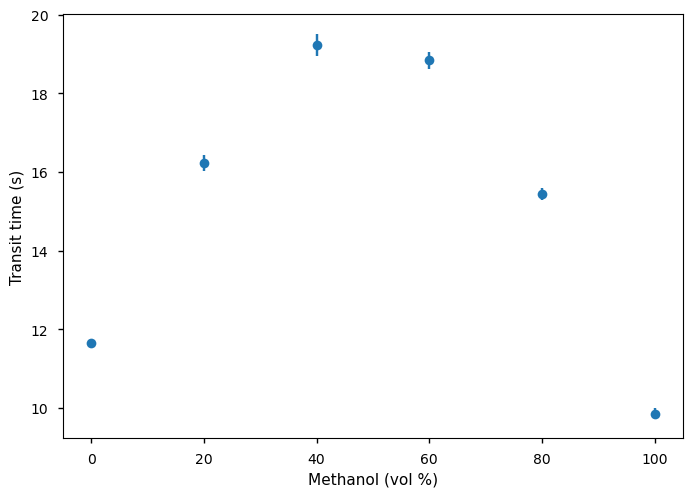

In [8]:
#| label: meoh_h2o_errplot
meoh_errfig, meoh_errax = plt.subplots()
meoh_errax.errorbar(x=meoh_h2o.mean().index, y=meoh_h2o.mean(), yerr=meoh_h2o.std(), capsize=3, linestyle='none', marker='o')
meoh_errax.set(xlabel='Methanol (vol %)', ylabel='Transit time (s)')
meoh_errfig.savefig('figures/meoh_h2o_errplot.png', bbox_inches='tight')

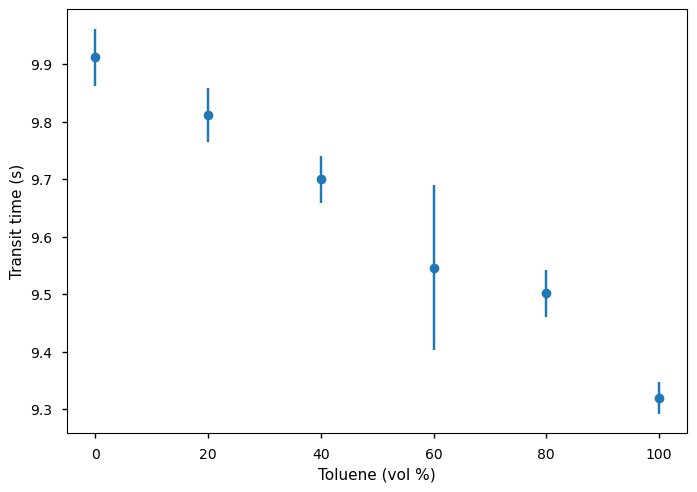

In [9]:
#| label: tol_xyl_errplot
tol_errfig, tol_errax = plt.subplots()
tol_errax.errorbar(x=tol_xyl.mean().index, y=tol_xyl.mean(), yerr=tol_xyl.std(), capsize=3, linestyle='none', marker='o')
tol_errax.set(xlabel='Toluene (vol %)', ylabel='Transit time (s)')
tol_errfig.savefig('figures/tol_xyl_errplot.png', bbox_inches='tight')

Determine viscosity based on density and flow time: $\eta = \frac{\pi r^4 P t}{8 V L} = {k_\text{inst} \rho t}$. The value for $k_\text{inst}$ can be found by using the values for pure H{sub}`2`O, as the density and viscosity are well known. 

In [10]:
k_inst_list = [ref_df["water"]["viscosity"] / (meoh_h2o[0].mean() * ref_df["water"]["density"]),
               ref_df["methanol"]["viscosity"] / (meoh_h2o[100].mean() * ref_df["methanol"]["density"]),
               ref_df["toluene"]["viscosity"] / (tol_xyl[100].mean() * ref_df["toluene"]["density"]),
               ref_df["p-xylene"]["viscosity"] / (tol_xyl[0].mean() * ref_df["p-xylene"]["density"])]
k_inst, k_err = np.mean(k_inst_list), np.std(k_inst_list)
k_inst, k_err/k_inst

(7.16679792689444e-05, 0.04185815307043047)

In [11]:
meoh_h2o_summary = pd.DataFrame(meoh_h2o.mean(), columns=['t_avg'])
meoh_h2o_summary['density'] = meoh_h2o_summary.index * 0.01 * ref_df['methanol']['density'] + \
                            ((1 - meoh_h2o_summary.index * 0.01) * ref_df['water']['density'])
meoh_h2o_summary['viscosity'] = k_inst * meoh_h2o_summary['density'] * meoh_h2o_summary['t_avg']
meoh_h2o_summary['fluidity (exp)'] = 1 / meoh_h2o_summary['viscosity']
meoh_h2o_summary['fluidity (eq.4)'] = fluidity_eq4(meoh_h2o_summary.index, 'methanol', 'water')
meoh_h2o_summary['fluidity (eq.6)'] = fluidity_eq6(meoh_h2o_summary.index, 'methanol', 'water')
meoh_h2o_summary

,t_avg,density,viscosity,fluidity (exp),fluidity (eq.4),fluidity (eq.6)
0,11.648,0.997050,0.000832,1201.452321,1123.570257,1123.570257
20,16.236,0.954906,0.001111,899.984802,1194.970598,1180.196623
40,19.236,0.912762,0.001258,794.698734,1286.824550,1257.261703
60,18.836,0.870618,0.001175,850.860802,1409.390231,1367.987564
80,15.452,0.828474,0.000917,1089.961750,1581.162423,1539.767333
100,9.860,0.786330,0.000556,1799.670843,1839.215758,1839.215758


In [12]:
tol_xyl_summary = pd.DataFrame(tol_xyl.mean(), columns=['t_avg'])
tol_xyl_summary['density'] = tol_xyl_summary.index * 0.01 * ref_df['p-xylene']['density'] + \
                            ((1 - tol_xyl_summary.index * 0.01) * ref_df['toluene']['density'])
tol_xyl_summary['viscosity'] = k_inst * tol_xyl_summary['density'] * tol_xyl_summary['t_avg']
tol_xyl_summary['fluidity (exp)'] = 1 / tol_xyl_summary['viscosity']
tol_xyl_summary['fluidity (eq.4)'] = fluidity_eq4(tol_xyl_summary.index, 'toluene', 'p-xylene')
tol_xyl_summary['fluidity (eq.6)'] = fluidity_eq6(tol_xyl_summary.index, 'toluene', 'p-xylene')
tol_xyl_summary

,t_avg,density,viscosity,fluidity (exp),fluidity (eq.4),fluidity (eq.6)
0,9.912,0.862240,0.000613,1632.621010,1645.857541,1645.857541
20,9.812,0.861992,0.000606,1649.734535,1682.816663,1681.458019
40,9.700,0.861744,0.000599,1669.263273,1717.632807,1715.698376
60,9.546,0.861496,0.000589,1696.680800,1750.487105,1748.648514
80,9.502,0.861248,0.000587,1705.028286,1781.540834,1780.374367
100,9.320,0.861000,0.000575,1738.824604,1810.938066,1810.938066


In [13]:
ref_df # compare reference viscosities with experimental values above. Should be close, related to st.dev. of k_inst

,water,methanol,toluene,p-xylene
viscosity,0.00089,0.000544,0.000552,0.000608
density,0.99705,0.786330,0.862240,0.861000
MM,18.01000,32.040000,92.170000,106.200000


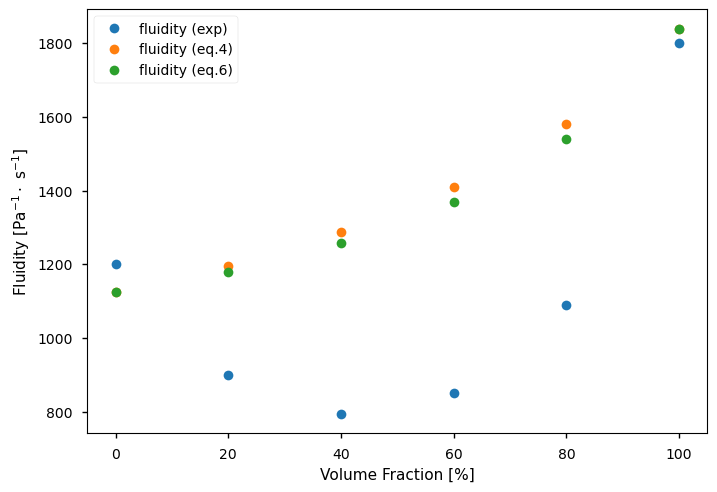

In [14]:
#| label: plt_meoh_fluidity
meoh_fluid_ax = meoh_h2o_summary.plot(y=['fluidity (exp)', 'fluidity (eq.4)', 'fluidity (eq.6)'], marker='o', linewidth=0)
# plt.title('Experimental and Calculated Fluidity, Methanol/Water Mixture')
meoh_fluid_ax.set(xlabel='Volume Fraction [%]', ylabel='Fluidity [Pa$^{-1}\\cdot$ s$^{-1}$]')
meoh_fluid_ax.figure.savefig('figures/meoh_fluidity.png', bbox_inches='tight')

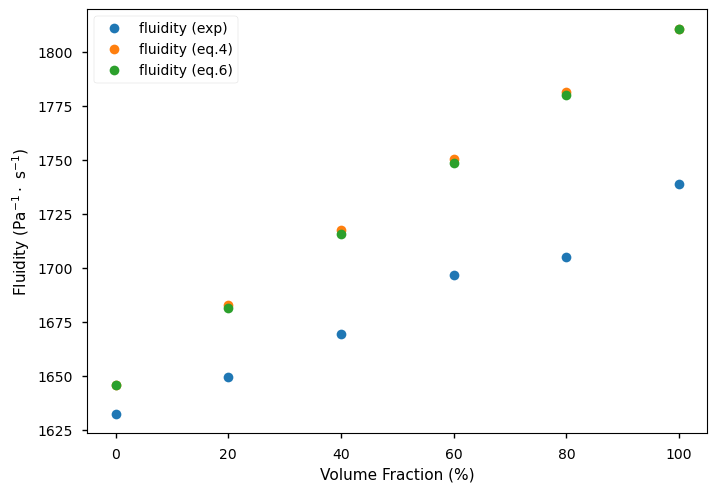

In [15]:
#| label: plt_tol_fluidity
tol_fluid_ax = tol_xyl_summary.plot(y=['fluidity (exp)', 'fluidity (eq.4)', 'fluidity (eq.6)'], marker='o', linewidth=0)
# plt.title('Experimental and Calculated Fluidity, Toluene/p-Xylene Mixture')
tol_fluid_ax.set(xlabel='Volume Fraction (%)', ylabel='Fluidity (Pa$^{-1}\\cdot$ s$^{-1}$)')
tol_fluid_ax.figure.savefig('figures/tol_fluidity.png', bbox_inches='tight')

## Results and Discussion

Several flow time trials were performed until the measurements agreed within 0.5 seconds for each solution mixture. These results are tabulated in [](#meoh_h2o_raw) and [](#tol_xyl_raw). [](#time_errplot) shows the average times with standard deviations represented by the error bars on each point. It is worth noting that the apparently "large" error in the 60% point in the toluene plot is enhanced by the much smaller _y_-axis in that plot. The range of times for _all_ of the toluene mixtures was only {eval}`(tol_xyl.max().max() - tol_xyl.min().min()).round(2)` seconds, while the the span of values for just the 40% methanol solution was {eval}`(meoh_h2o[40].max() - meoh_h2o[40].min()).round(2)` seconds. Precision and accuracy in the experiment could be improved by automating the timing portion of the experiment though the use of recording technology. Additionally, though the viscometer bulb was immersed in a temperature-controlled water bath, the upper portion of the viscometer was above the water level. Temperature fluctuations in the room would rapidly affect the small volume of liquid passing through the capillary. All of the reference values in [](#tbl_ref_data) are temperature dependent and the values given are only valid at 25 °C. 

:::{table} Flow time measurements for mixtures of methanol and water (in seconds). Samples are labeled as volume percent methanol in the mixture. 
:label: meoh_h2o_raw
:align: center

{eval}`meoh_h2o.style.format(precision=2).relabel_index(cols, axis=0)` 

:::

:::{table} Flow time measurements for mixtures of toluene and _p_-xylene (in seconds). Samples are labeled as volume percent _p_-xylene in the mixture. 
:label: tol_xyl_raw
:align: center

{eval}`tol_xyl.style.format(precision=2).relabel_index(cols, axis=0)`

:::

:::{figure} 
:name: time_errplot
:align: center

(meoh_errplot)=
![Transit times for various methanol/water mixtures](figures/meoh_h2o_errplot.png)

(tol_errplot)=
![Transit times for various toluene/_p_-xylene mixtures](figures/tol_xyl_errplot.png)

Average times and standard deviations for mixtures of [methanol/water](#meoh_errplot) and [toluene/_p_-xylene](#tol_errplot). Values on the _x_-axis represent the percentage of the first component in the solution by volume. 
:::

<!-- :::{figure} #meoh_h2o_errplot
:name: meoh_errplot
:alt: Transit times for various methanol/water mixtures
:placeholder: figures/meoh_h2o_errplot.png
:align: left
Average times and standard deviations for mixtures of methanol and water. Values on the _x_-axis represent the percentage of methanol in the solution by volume. 
:::

:::{figure} #tol_xyl_errplot
:name: tol_errplot
:alt: Transit times for various toluene/p-xylene mixtures
:placeholder: figures/tol_xyl_errplot.png
:align: left
Average times and standard deviations for mixtures of toluene and _p_-xylene. Values on the _x_-axis represent the percentage of toluene in the solution by volume. 
::: -->

:::{table} Reference data for pure substances
:label: tbl_ref_data
:align: center

{eval}`ref_df.style` 

:::

The instrumentation constant, $k_\text{inst} = \eta_r / (\rho_r t_r)$ of the viscometer was calculated for each of the pure liquids (0% and 100% fractions) using the data in [](#tbl_ref_data), then the resulting values were averaged. Subsequent calculations all used the average value for $k_\text{inst}$. The flow times in [](#meoh_h2o_raw) and [](#tol_xyl_raw) were averaged over the five trials, then the average times were used to calculate experimental viscosity ($\eta$) and fluidity ($F$) values for each mixture according to 
:::{math}
:label: exp_viscosity
\eta = k_\text{inst} \rho_\text{soln} t
:::
and 
:::{math}
:label: exp_fluidity
F = 1 / \eta
:::

In theory, for ideal mixtures (_i.e.,_ compounds which do not interact with each other), the fluidity of the mixture should be a linear combination of the components, 
:::{math}
:label: lin_fluidity
F \simeq x_A F_A + x_B F_B
:::
for two components $A$ and $B$, where $x_i$ is the mole fraction of component $i$. Alternatively, by integrating Poiseuille's Law (see Ref. 1), the viscosities can be related through [Eq. %s](#log_visc). 
:::{math}
:label: log_visc
\ln{\eta} = x_A \ln{\eta_A} + x_B \ln{\eta_B}
:::

:::{table} Results summary for methanol/water mixtures. 
:label: meoh_results
:align: center

{eval}`meoh_h2o_summary.style.format(precision=2)` 

:::
:::{table} Results summary for toluene/_p_-xylene mixtures. 
:label: tol_results
:align: center

{eval}`tol_xyl_summary.style.format(precision=2)` 

:::

:::{figure} 
:name: fluidity_plots
:align: center

(meoh_fluidplot)=
![Experimental and theoretical fluidity values for various methanol/water mixtures](figures/meoh_fluidity.png)

(tol_fluidplot)=
![Experimental and theoretical fluidity values for various toluene/_p_-xylene mixtures](figures/tol_fluidity.png)

Average times and standard deviations for mixtures of [methanol/water](#meoh_errplot) and [toluene/_p_-xylene](#tol_errplot). Values on the _x_-axis represent the percentage of the first component in the solution by volume. 
:::

[](#meoh_results) and [](#tol_results) show the results of these calculations for the experimental data. The experimental and theoretical fluidity values are plotted in [](#meoh_fluidplot) and [](#tol_fluidplot). The clear deviation from ideal behavior is visible in [](#meoh_fluidplot) where the experimental data for the methanol/water mixture take on a distinctly quadratic appearance when compared to the expected linear trend seen in the theoretical values. The plotted data also show a slight deviation for the theoretical values calculated using [](#lin_fluidity) versus [](#log_visc). This deviation is expected, as the logarithmic transformation in [](#log_visc) introduces a non-linear element to the calculation, but the plots show the non-linearity is a relatively minor perturbation to the trend. 

A likely source of the non-ideal behavior in the methanol/water mixture is the strong polar character of the two molecules. As stated in the lab manual, the assumption for ideal behavior is that the components in the mixture do not interact, and it is well known that water and alcohols have strong interactions through hydrogen bonding. In contrast, toluene and _p_-xylene have only weak intermolecular interactions through van der Waals forces. 

## Conclusion

The data collected in this exercise helped to illustrate the role of intermolecular forces on the viscosity trends in a mixture. By combining two non-polar liquids and two highly-polar liquids, the 

## References

1. Hunter College CHEM 357 Lab Manual, "Viscosity of Binary Solutions"
2. Nain, A. K.; Chandra, P.; Pandey, J. D.; Gopal, S. Densities, Refractive Indices, and Excess Properties of Binary Mixtures of 1,4-Dioxane with Benzene, Toluene, _o_-Xylene, _m_-Xylene, _p_-Xylene, and Mesitylene at Temperatures from (288.15 to 318.15) K. _J. Chem. Eng. Data_ (2008), **53**, 2654-2665,  DOI: 10.1021/je800579j
3. Meng, X.; Gu, X.; Wu, J.; Vesovic, V. Viscosity measurements of _ortho_-xylene, _meta_-xylene, _para_-xylene and ethylbenzene. _J Chem. Thermodyn._, **95**, 116-123, (2016) DOI: 10.1016/j.jct.2015.11.027
4. Linstrom, P. and Mallard, W., The NIST Chemistry WebBook: A Chemical Data Resource on the Internet, _J. Chem. Eng. Data_ (2001) (Accessed March 13, 2024) 